# **11 - Neighbourhood-aware trend models with median loss and recalibration**

This notebook answers the review findings F-05, F-08, F-10, F-11 and F-15 and sections 4.2 and 4.3 of `reports/REVIEW_MODELING.md`. The review numbers were exploratory (they looked at 2025); every number below is recomputed here and printed.

**What is new.**
- `features.NeighbourhoodGrouper`: grouped `legal_dong` (district + neighbourhood). Levels with fewer rows than a minimum count **in the fit window** go to the OTHER level of their own district; neighbourhoods never seen in the fit window map to the same OTHER level; at most 254 levels. The minimum count (10, 30 or 100) is chosen by the 3-fold time CV inside the fit window, together with the other settings.
- New models (both tracks): `hgb_detrended_ld` and `hybrid_hgb_ld` (squared loss) and `hgb_detrended_ld_median` and `hybrid_hgb_ld_median` (median loss, `quantile=0.5` on `log1p`). The detrended model is tuned on its residual target, the hybrid structure model on `y_adj`.
- `_recal` models: `hgb_detrended_ld_median_recal` and `hybrid_hgb_ld_median_recal` multiply the predictions by one global scale factor estimated on the **last CV fold of the fit window** (the same model fit on the rows before that fold predicts it; factor = sum of actuals / sum of predictions). It is an explicit model component; nothing from the evaluation window enters it.

**Protocol (CLAUDE.md, rule 8, amended).**
- Settings are tuned separately inside each fit window (rows before 2023-01-01, before 2024-01-01 and before 2025-01-01) with `RandomizedSearchCV` over the 3-fold expanding-window CV, on the full fit window. The grid goes beyond `max_leaf_nodes=127`.
- Candidates are selected on the two pseudo-tests (fit before 2023 and test 2023; fit before 2024 and test 2024) with the one-standard-error rule on the most conservative of the row, month-block and district-block bootstrap standard errors. A model extrapolates only if its projected path changes beyond the last level.
- 2025 is evaluated once, at the end, for the shortlist. It never selects a model. The squared-loss `_ld` variants and the `_recal` variants reuse the settings tuned for the median-loss finalist of the same family.

**Limitations.** The random search samples only a small part of the grid (the number of candidates is printed); the earlier candidates keep the settings tuned for them in notebooks 02 to 08; 2025 was inspected in earlier iterations of this project (see the README), so the 2025 figures are not those of an untouched hold-out.

| block | question |
|---|---|
| 1 | How does the neighbourhood grouping behave in each fit window? |
| 2 | Tuning of the finalists (sample size, grid, best settings) |
| 3 | Pseudo-tests: new models against the earlier shortlist |
| 4 | Effect of each component: neighbourhood, median loss, recalibration |
| 5 | Month-by-month rescaling (upper bound, not a valid model) |
| 6 | Learning curve and window sensitivity |
| 7 | Repeat units vs new units |
| 8 | Error by predicted-price tier and building type |
| 9 | Selection, behavioural extrapolation and 2025 report |

In [1]:
import sys
import time
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'rent_model').exists())
sys.path.insert(0, str(ROOT / 'src'))

import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from rent_model import config
from rent_model.boosting import adjusted_wape_scorer, required_columns, tune_extended
from rent_model.compare import complexity_of, extrapolation_kind
from rent_model.data import load_clean
from rent_model.diagnostics import error_table, lot_available, price_tier, repeat_unit_flag
from rent_model.features import NeighbourhoodGrouper, build_features, build_target, select_track
from rent_model.hybrid import index_adjustment
from rent_model.io import save_run
from rent_model.metrics import all_metrics, wape
from rent_model.projection import FUTURE
from rent_model.pseudotest import WINDOWS, check_windows, pool, run_windows, select, window_split
from rent_model.recipes import ModelRecipe, ld_recipe_ids, projected_path
from rent_model.splits import temporal_split, window_folds
from rent_model.ts_index import hedonic_index
from rent_model.compare import classify_projection

pd.set_option('display.float_format', '{:,.4f}'.format)
pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 40)
plt.rcParams['figure.dpi'] = 100
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)

N_ITER = 12            # candidates sampled by each random search (3 folds each)
print('Random seed:', config.RANDOM_SEED, '| random-search candidates per tuning:', N_ITER)

Random seed: 42 | random-search candidates per tuning: 12


## Data, fit windows and candidates

In [2]:
df = load_clean(keep_lots=True)      # same rows as always; the lot numbers are kept only for the unit key of block 7
FULL_DATA = len(df) == config.EXPECTED_ROWS
check_windows()
FIT_END = {w['name']: w['fit_end'] for w in WINDOWS}
FIT_END['final'] = config.TEST_START
data = {}
for track, spec in config.TRACKS.items():
    df_t = select_track(df, track)
    train, test = temporal_split(df_t)
    data[track] = dict(df=df_t, train=train, test=test, target=spec['target'])
    sizes = [f"fit < {FIT_END[n]:%Y-%m-%d}: {int((df_t['contract_date'] < FIT_END[n]).sum()):,} rows" for n in FIT_END]
    print(f"{track}: " + ' | '.join(sizes) + f" | TEST 2025: {len(test):,} rows")

def fit_frame(track, name):
    d = data[track]['df']
    fit = d[d['contract_date'] < FIT_END[name]]
    assert fit['contract_date'].max() < FIT_END[name], 'an evaluation-window row reached the fit window'
    return fit

def features(frame, track):
    return build_features(frame, track, include_time=True, include_legal_dong=True)

nb10 = {t: json.loads((config.METRICS_DIR / f'pseudotest_{t}.json').read_text(encoding='utf-8')) for t in config.TRACKS}
OLD = {t: sorted({r['model_id'] for tab in ('table_unconstrained', 'table_extrapolating') for r in nb10[t][tab]}) for t in config.TRACKS}
NEW = ld_recipe_ids()
print('new candidates:', NEW)
for t in config.TRACKS:
    print(f'{t}: earlier shortlist re-run on the pseudo-tests ({len(OLD[t])} models, those listed in the selection tables of notebook 10):', OLD[t])

jeonse: fit < 2023-01-01: 50,327 rows | fit < 2024-01-01: 97,840 rows | fit < 2025-01-01: 138,848 rows | TEST 2025: 37,935 rows
wolse: fit < 2023-01-01: 50,860 rows | fit < 2024-01-01: 102,182 rows | fit < 2025-01-01: 152,714 rows | TEST 2025: 57,829 rows
new candidates: ['hgb_detrended_ld', 'hgb_detrended_ld_median', 'hybrid_hgb_ld', 'hybrid_hgb_ld_median', 'hgb_detrended_ld_median_recal', 'hybrid_hgb_ld_median_recal']
jeonse: earlier shortlist re-run on the pseudo-tests (16 models, those listed in the selection tables of notebook 10): ['baseline_district_type_area', 'hgb_detrended', 'hgb_detrended_median', 'hgb_legal_dong', 'hgb_legal_dong_median', 'hgb_static', 'hgb_static_median', 'hgb_time', 'hgb_time_median', 'hybrid_hgb', 'hybrid_hgb_median', 'hybrid_ridge', 'rf_detrended', 'ridge_static', 'ridge_time', 'ridge_time_rich']
wolse: earlier shortlist re-run on the pseudo-tests (16 models, those listed in the selection tables of notebook 10): ['baseline_district_type_area', 'hgb_detr

## 1) Neighbourhood grouping in each fit window

In [3]:
rows = []
for track in config.TRACKS:
    for w in WINDOWS:
        fit, test = window_split(data[track]['df'], w)
        dong_fit, dong_test = features(fit, track)[config.LEGAL_DONG_FEATURE], features(test, track)[config.LEGAL_DONG_FEATURE]
        seen = set(dong_fit)
        for min_count in (10, 30, 100):
            g = NeighbourhoodGrouper(min_count=min_count).fit(dong_fit.to_numpy().reshape(-1, 1))
            assert g.n_fit_rows_ == len(fit) and fit['contract_date'].max() < w['fit_end']      # only fit-window rows define the levels
            is_other = lambda s: pd.Series(g.group(s.to_numpy().reshape(-1, 1))).str.endswith('OTHER').mean() * 100
            rows.append({'track': track, 'fit before': f"{w['fit_end']:%Y-%m-%d}", 'min count': min_count, 'fit rows': len(fit),
                         'neighbourhoods in fit': dong_fit.nunique(), 'levels produced': len(g.levels_),
                         'fit rows in OTHER (%)': is_other(dong_fit), 'evaluation rows in OTHER (%)': is_other(dong_test),
                         'evaluation rows with an unseen neighbourhood (%)': float((~dong_test.isin(seen)).mean() * 100)})
display(pd.DataFrame(rows).set_index(['track', 'fit before', 'min count']))
print('assertion passed: the levels of every grouper are defined by the rows before the fit end only')

fit rows  neighbourhoods in fit  levels produced  fit rows in OTHER (%)  evaluation rows in OTHER (%)  evaluation rows with an unseen neighbourhood (%)
track  fit before min count                                                                                                                                                         
jeonse 2023-01-01 10            50327                    367              254                 2.3347                        2.6161                                            0.1368
                  30            50327                    367              244                 2.8553                        3.1591                                            0.1368
                  100           50327                    367              167                12.4625                       12.9901                                            0.1368
       2024-01-01 10            97840                    383              254                 2.4285                        2.5532                                            0.0024
                  30            97840                    383              254                 2.4285                        2.5532                                            0.0024
                  100           97840                    383              215                 5.3465                        5.7013                                            0.0024
wolse  2023-01-01 10            50860                    383              254                 2.8490                        3.3631                                            0.0721
                  30            50860                    383              244                 3.3740                        3.8950                                            0.0721
                  100           50860                    383              173                11.4157                       12.2813                                            0.0721
       2024-01-01 10           102182                    393              254                 2.9888                        3.1901                                            0.0119
                  30           102182                    393              254                 2.9888                        3.1901                                            0.0119
                  100          102182                    393              212                 6.0676                        6.6235                                            0.0119

assertion passed: the levels of every grouper are defined by the rows before the fit end only


**Interpretation.** The grouped feature has at most 254 levels in every case (kept neighbourhoods plus one OTHER level per district). With a minimum count of 10 or 30, between 2.3347% and 3.3740% of the fit rows fall in an OTHER level and evaluation rows fall in it slightly more often (2.5532% to 3.8950%); with a minimum count of 100 the share rises to between 5.3465% and 12.4625% of the fit rows. The share of evaluation rows whose neighbourhood was never seen in the fit window is small (0.0024% to 0.1368% in Jeonse and 0.0119% to 0.0721% in Wolse), so the OTHER level handles the unseen case without losing much information. The assertion confirms that the levels of every grouper are defined by the rows before the fit end only.

## 2) Tuning of the finalists inside each fit window

In [4]:
tuned, rows = {}, []
for track in config.TRACKS:
    for name in FIT_END:
        fit = fit_frame(track, name)
        folds = window_folds(fit)
        X, y = features(fit, track), build_target(fit, track)
        t0 = time.time()
        p_det, tab_det, n_det = tune_extended('detrended', X[required_columns('detrended', True)], y, folds, n_iter=N_ITER, quantile=0.5, neighbourhood=True)
        index = hedonic_index(fit, track, last_month=FIT_END[name] - pd.offsets.MonthBegin(1))
        adj = index_adjustment(index, fit['contract_month'])
        X_h = X[required_columns('static', True)].assign(adj_log=adj)
        p_hyb, tab_hyb, n_hyb = tune_extended('static', X_h, y - adj, folds, n_iter=N_ITER, quantile=0.5, neighbourhood=True, scorer=adjusted_wape_scorer)
        assert n_det == n_hyb == len(fit) and all(fit.iloc[v]['contract_date'].max() < FIT_END[name] for _, v in folds)
        tuned[(track, name)] = {'detrended': p_det, 'hybrid': p_hyb}
        for family, params, table in (('detrended (residual target)', p_det, tab_det), ('hybrid structure (y_adj)', p_hyb, tab_hyb)):
            rows.append({'track': track, 'fit window': name, 'finalist': family, 'fit rows': len(fit), 'folds (train/valid rows)': ' '.join(f'{len(a)}/{len(b)}' for a, b in folds),
                         'candidates': N_ITER, 'best CV WAPE': table.loc[0, 'cv_wape_mean'], **params})
        print(f'{track} / {name}: tuned in {time.time() - t0:,.0f} s on {len(fit):,} rows')
tuning = pd.DataFrame(rows).set_index(['track', 'fit window', 'finalist'])
display(tuning)
print('Grid:', {k: v for k, v in __import__('rent_model.boosting', fromlist=['x']).EXTENDED_PARAM_DISTRIBUTIONS.items()})

jeonse / 2023: tuned in 667 s on 50,327 rows


jeonse / 2024: tuned in 810 s on 97,840 rows


jeonse / final: tuned in 963 s on 138,848 rows


wolse / 2023: tuned in 529 s on 50,860 rows


wolse / 2024: tuned in 714 s on 102,182 rows


wolse / final: tuned in 815 s on 152,714 rows


fit rows              folds (train/valid rows)  candidates  best CV WAPE  learning_rate  max_iter  max_leaf_nodes  min_samples_leaf  l2_regularization  min_frequency
track  fit window finalist                                                                                                                                                                                          
jeonse 2023       detrended (residual target)     50327      27899/8604 36503/7429 43932/6395          12       17.0030         0.0500       300             255                20             0.0000             30
                  hybrid structure (y_adj)        50327      27899/8604 36503/7429 43932/6395          12       16.4566         0.0500       300             255                20             0.0000             30
       2024       detrended (residual target)     97840   50327/16635 66962/15427 82389/15451          12       16.5410         0.0500       300             255                20             0.0000             30
                  hybrid structure (y_adj)        97840   50327/16635 66962/15427 82389/15451          12       14.9356         0.1000       600             127                20            10.0000             10
       final      detrended (residual target)    138848  50327/32062 82389/30026 112415/26433          12       15.8137         0.0500       300             255                20             0.0000             30
                  hybrid structure (y_adj)       138848  50327/32062 82389/30026 112415/26433          12       14.8545         0.0500       300             255                20             0.0000             30
wolse  2023       detrended (residual target)     50860      27518/8437 35955/7179 43134/7726          12       38.2840         0.0500       300             255                20             0.0000             30
                  hybrid structure (y_adj)        50860      27518/8437 35955/7179 43134/7726          12       38.3896         0.0500       300             255                20             0.0000             30
       2024       detrended (residual target)    102182   50860/17992 68852/16717 85569/16613          12       36.3689         0.0500       300             255                20             0.0000             30
                  hybrid structure (y_adj)       102182   50860/17992 68852/16717 85569/16613          12       36.6736         0.0500       300             255                20             0.0000             30
       final      detrended (residual target)    152714  50860/34709 85569/31839 117408/35306          12       38.7353         0.0500       300             255                20             0.0000             30
                  hybrid structure (y_adj)       152714  50860/34709 85569/31839 117408/35306          12       39.3322         0.1000       600             127                20            10.0000             10

Grid: {'learning_rate': [0.05, 0.1], 'max_iter': [300, 600], 'max_leaf_nodes': [31, 63, 127, 255], 'min_samples_leaf': [20, 50, 100], 'l2_regularization': [0.0, 1.0, 10.0], 'min_frequency': [10, 30, 100]}


**Interpretation.** Each search uses the full fit window: 50,327, 97,840 and 138,848 rows in Jeonse and 50,860, 102,182 and 152,714 rows in Wolse. The Wolse final window has more than 150,000 rows; the Jeonse final window has 138,848 rows, which is the whole window, so the 150,000-row target cannot be reached without rows of the evaluation year. Each search samples 12 candidates of the grid (three folds each) and takes between 529 and 963 seconds. The best settings are stable across windows: `max_leaf_nodes` is 255 (the largest value of the grid) in most rows, `min_samples_leaf` is 20 (the smallest value) in every row, `max_iter` is 300 (the smallest) in most rows and `min_frequency` is 30 in most rows, with 10 and 100 appearing only for some hybrid searches. Several settings are therefore at the edge of the grid, and a wider grid might find a better setting; only 12 candidates of the grid are sampled in each search. The best CV WAPE of the final window is 15.8137% (detrended) and 14.8545% (hybrid) in Jeonse and 38.7353% and 39.3322% in Wolse.

## 3) Pseudo-tests: new models against the earlier shortlist

In [5]:
def make_recipe(track, model_id, window_name):
    if model_id in NEW:
        kind = 'detrended' if 'detrended' in model_id else 'hybrid'
        return ModelRecipe(model_id, track, params=tuned[(track, window_name)][kind])
    return ModelRecipe(model_id, track)

pseudo, window_recipes = {t: {} for t in config.TRACKS}, {t: {} for t in config.TRACKS}
for track in config.TRACKS:
    t0 = time.time()
    for model_id in [*OLD[track], *NEW]:
        recipes = {w['name']: make_recipe(track, model_id, w['name']) for w in WINDOWS}
        pseudo[track][model_id] = run_windows(recipes, data[track]['df'], lambda f, t=track: features(f, t))
        window_recipes[track][model_id] = recipes
    print(f'{track}: {len(OLD[track]) + len(NEW)} candidates run on both windows in {time.time() - t0:,.0f} s')

def pooled_row(track, model_id):
    res = pseudo[track][model_id]
    y, preds, _, _ = pool({model_id: res})
    return {'wape_2023': res['2023']['metrics']['wape_pct'], 'wape_2024': res['2024']['metrics']['wape_pct'], 'wape_pooled': wape(y, preds[model_id]),
            'agg_bias_2023': res['2023']['metrics']['aggregate_bias_pct'], 'agg_bias_2024': res['2024']['metrics']['aggregate_bias_pct']}

pooled = {t: pd.DataFrame({m: pooled_row(t, m) for m in pseudo[t]}).T.sort_values('wape_pooled') for t in config.TRACKS}
for track in config.TRACKS:
    print(f'{track}: pseudo-test WAPE % and aggregate bias %, sorted by the pooled WAPE')
    display(pooled[track])
if FULL_DATA:
    diff = max(abs(pooled[t].loc[m, 'wape_pooled'] - nb10[t]['candidates'][m]['wape_pooled']) for t in config.TRACKS for m in OLD[t])
    print(f'largest difference with the pooled WAPE saved by notebook 10 for the {sum(len(v) for v in OLD.values())} earlier candidates: {diff:.2e}')
    assert diff < 1e-6

jeonse: 22 candidates run on both windows in 591 s


wolse: 22 candidates run on both windows in 377 s
jeonse: pseudo-test WAPE % and aggregate bias %, sorted by the pooled WAPE


,wape_2023,wape_2024,wape_pooled,agg_bias_2023,agg_bias_2024
hgb_detrended_ld_median_recal,15.8080,14.3281,15.0935,0.8078,0.6468
hybrid_hgb_ld_median_recal,16.4485,14.0916,15.3106,-6.0421,-0.5268
hybrid_hgb_ld_median,16.0303,14.9619,15.5145,1.8601,-5.3196
hybrid_hgb_ld,15.8017,15.2071,15.5147,0.1031,-6.1477
hgb_detrended_ld,17.0450,14.2566,15.6988,6.9693,0.9339
hgb_detrended_ld_median,18.2155,14.3287,16.3390,9.6798,0.9453
hgb_legal_dong,16.6457,16.1043,16.3843,4.8101,-8.3346
hgb_legal_dong_median,17.1561,16.0072,16.6014,6.1733,-7.9769
hgb_time_median,17.3273,17.3456,17.3361,-1.5373,-4.2469
hgb_time,17.8333,17.6726,17.7557,-2.8507,-5.2603


wolse: pseudo-test WAPE % and aggregate bias %, sorted by the pooled WAPE


,wape_2023,wape_2024,wape_pooled,agg_bias_2023,agg_bias_2024
hgb_detrended_ld_median_recal,37.3755,41.1020,39.2218,-0.7509,2.5434
hgb_detrended_ld_median,37.4050,41.0868,39.2291,-3.6580,1.9205
hgb_legal_dong_median,37.7919,41.7349,39.7454,-6.2621,-3.7336
hybrid_hgb_ld_median,38.2631,41.4159,39.8252,-11.0359,-4.3073
hgb_detrended_median,37.6106,42.7934,40.1784,-4.7512,1.6131
hgb_static_median,37.8595,42.9401,40.3767,-7.9088,-4.1413
hgb_time_median,38.2498,43.2210,40.7128,-7.6039,-0.9812
hybrid_hgb_median,38.5561,42.9303,40.7233,-11.9356,-4.6066
hgb_detrended_ld,39.2466,42.4835,40.8503,-13.6219,-10.7330
hybrid_hgb_ld_median_recal,41.1087,41.2752,41.1911,-20.9601,-2.6191


largest difference with the pooled WAPE saved by notebook 10 for the 32 earlier candidates: 0.00e+00


**Interpretation.** The earlier candidates reproduce the pooled WAPE saved by notebook 10 exactly (largest difference 0.00e+00), so the new models are compared with the same references. In Jeonse the best pooled pseudo-test WAPE is 15.0935% (`hgb_detrended_ld_median_recal`), followed by `hybrid_hgb_ld_median_recal` (15.3106%), `hybrid_hgb_ld_median` (15.5145%), `hybrid_hgb_ld` (15.5147%) and `hgb_detrended_ld` (15.6988%); the earlier leader `hgb_legal_dong` has 16.3843% and `hgb_legal_dong_median` 16.6014%. In Wolse the best are `hgb_detrended_ld_median_recal` (39.2218%) and `hgb_detrended_ld_median` (39.2291%), ahead of `hgb_legal_dong_median` (39.7454%), `hybrid_hgb_ld_median` (39.8252%) and `hgb_detrended_median` (40.1784%). The Wolse squared-loss models stay far behind (`hgb_detrended_ld` 40.8503% with an aggregate bias of -10.7330% in 2024). The 2024 pseudo-test WAPE of the best models is 14.3281% in Jeonse and 41.0868% in Wolse (`hgb_detrended_ld_median`).

## 4) Effect of each component

In [6]:
STEPS = [
    ('detrended family', 'neighbourhood (squared loss)', 'hgb_detrended', 'hgb_detrended_ld'),
    ('detrended family', 'median loss (no neighbourhood)', 'hgb_detrended', 'hgb_detrended_median'),
    ('detrended family', 'median loss (with neighbourhood)', 'hgb_detrended_ld', 'hgb_detrended_ld_median'),
    ('detrended family', 'recalibration', 'hgb_detrended_ld_median', 'hgb_detrended_ld_median_recal'),
    ('hybrid family', 'neighbourhood (squared loss)', 'hybrid_hgb', 'hybrid_hgb_ld'),
    ('hybrid family', 'median loss (no neighbourhood)', 'hybrid_hgb', 'hybrid_hgb_median'),
    ('hybrid family', 'median loss (with neighbourhood)', 'hybrid_hgb_ld', 'hybrid_hgb_ld_median'),
    ('hybrid family', 'recalibration', 'hybrid_hgb_ld_median', 'hybrid_hgb_ld_median_recal'),
]
rows = []
for track in config.TRACKS:
    for family, component, before, after in STEPS:
        b, a = pooled[track].loc[before], pooled[track].loc[after]
        rows.append({'track': track, 'family': family, 'component': component, 'from': before, 'to': after,
                     'WAPE 2023 from': b['wape_2023'], 'WAPE 2023 to': a['wape_2023'], 'WAPE 2024 from': b['wape_2024'], 'WAPE 2024 to': a['wape_2024'],
                     'pooled from': b['wape_pooled'], 'pooled to': a['wape_pooled'], 'pooled change (pts)': a['wape_pooled'] - b['wape_pooled'],
                     'bias 2024 from': b['agg_bias_2024'], 'bias 2024 to': a['agg_bias_2024']})
components = pd.DataFrame(rows).set_index(['track', 'family', 'component'])
display(components[['from', 'to', 'WAPE 2024 from', 'WAPE 2024 to', 'pooled from', 'pooled to', 'pooled change (pts)', 'bias 2024 from', 'bias 2024 to']])

rows = []
for track in config.TRACKS:
    for model_id in ('hgb_detrended_ld_median_recal', 'hybrid_hgb_ld_median_recal'):
        for w in WINDOWS:
            r = window_recipes[track][model_id][w['name']]
            assert pd.Timestamp(r.recal_info_['valid_last']) < w['fit_end'] and pd.Timestamp(r.recal_info_['valid_start']) < w['fit_end']
            rows.append({'track': track, 'model_id': model_id, 'fit before': f"{w['fit_end']:%Y-%m-%d}", 'factor': r.recal_factor_, **r.recal_info_})
display(pd.DataFrame(rows).set_index(['track', 'model_id', 'fit before']))
print('assertion passed: the validation block that sets each scale factor ends before the fit end')

from                             to  WAPE 2024 from  WAPE 2024 to  pooled from  pooled to  pooled change (pts)  bias 2024 from  bias 2024 to
track  family           component                                                                                                                                                                                        
jeonse detrended family neighbourhood (squared loss)                hgb_detrended               hgb_detrended_ld         17.1627       14.2566      18.3481    15.6988              -2.6493          0.8066        0.9339
                        median loss (no neighbourhood)              hgb_detrended           hgb_detrended_median         17.1627       17.2714      18.3481    18.8942               0.5461          0.8066        0.8606
                        median loss (with neighbourhood)         hgb_detrended_ld        hgb_detrended_ld_median         14.2566       14.3287      15.6988    16.3390               0.6402          0.9339        0.9453
                        recalibration                     hgb_detrended_ld_median  hgb_detrended_ld_median_recal         14.3287       14.3281      16.3390    15.0935              -1.2455          0.9453        0.6468
       hybrid family    neighbourhood (squared loss)                   hybrid_hgb                  hybrid_hgb_ld         17.8245       15.2071      17.9284    15.5147              -2.4137         -6.3972       -6.1477
                        median loss (no neighbourhood)                 hybrid_hgb              hybrid_hgb_median         17.8245       17.5636      17.9284    17.9451               0.0167         -6.3972       -5.6518
                        median loss (with neighbourhood)            hybrid_hgb_ld           hybrid_hgb_ld_median         15.2071       14.9619      15.5147    15.5145              -0.0002         -6.1477       -5.3196
                        recalibration                        hybrid_hgb_ld_median     hybrid_hgb_ld_median_recal         14.9619       14.0916      15.5145    15.3106              -0.2038         -5.3196       -0.5268
wolse  detrended family neighbourhood (squared loss)                hgb_detrended               hgb_detrended_ld         43.7562       42.4835      41.5765    40.8503              -0.7262        -11.0657      -10.7330
                        median loss (no neighbourhood)              hgb_detrended           hgb_detrended_median         43.7562       42.7934      41.5765    40.1784              -1.3982        -11.0657        1.6131
                        median loss (with neighbourhood)         hgb_detrended_ld        hgb_detrended_ld_median         42.4835       41.0868      40.8503    39.2291              -1.6212        -10.7330        1.9205
                        recalibration                     hgb_detrended_ld_median  hgb_detrended_ld_median_recal         41.0868       41.1020      39.2291    39.2218              -0.0073          1.9205        2.5434
       hybrid family    neighbourhood (squared loss)                   hybrid_hgb                  hybrid_hgb_ld         44.7476       43.4845      42.9482    42.3116              -0.6366        -16.4237      -16.0119
                        median loss (no neighbourhood)                 hybrid_hgb              hybrid_hgb_median         44.7476       42.9303      42.9482    40.7233              -2.2249        -16.4237       -4.6066
                        median loss (with neighbourhood)            hybrid_hgb_ld           hybrid_hgb_ld_median         43.4845       41.4159      42.3116    39.8252              -2.4864        -16.0119       -4.3073
                        recalibration                        hybrid_hgb_ld_median     hybrid_hgb_ld_median_recal         41.4159       41.2752      39.8252    41.1911               1.3660         -4.3073       -2.6191

factor valid_start  valid_last  n_valid  n_fit_aux
track  model_id                      fit before                                                    
jeonse hgb_detrended_ld_median_recal 2023-01-01  0.9191  2022-11-01  2022-12-31     6395      43932
                                     2024-01-01  0.9970  2023-09-01  2023-12-31    15451      82389
       hybrid_hgb_ld_median_recal    2023-01-01  0.9224  2022-11-01  2022-12-31     6395      43932
                                     2024-01-01  1.0506  2023-09-01  2023-12-31    15451      82389
wolse  hgb_detrended_ld_median_recal 2023-01-01  1.0302  2022-11-01  2022-12-31     7726      43134
                                     2024-01-01  1.0061  2023-09-01  2023-12-31    16613      85569
       hybrid_hgb_ld_median_recal    2023-01-01  0.8884  2022-11-01  2022-12-31     7726      43134
                                     2024-01-01  1.0176  2023-09-01  2023-12-31    16613      85569

assertion passed: the validation block that sets each scale factor ends before the fit end


**Interpretation.** Pooled pseudo-test change in WAPE points (negative is better). Neighbourhood with the squared loss: -2.6493 (detrended) and -2.4137 (hybrid) in Jeonse, and -0.7262 and -0.6366 in Wolse. Median loss on top of the neighbourhood: +0.6402 (detrended) and -0.0002 (hybrid) in Jeonse, but -1.6212 and -2.4864 in Wolse, where it also moves the 2024 aggregate bias from -10.7330% to 1.9205% (detrended) and from -16.0119% to -4.3073% (hybrid). Recalibration: -1.2455 and -0.2038 in Jeonse, -0.0073 (detrended) and +1.3660 (hybrid) in Wolse. The scale factors are noisy because the last CV fold of a short fit window is short: for the hybrid in Wolse the factor is 0.8884 in the first window and 1.0176 in the second, and the recalibrated hybrid is worse than the plain one on the pseudo-tests (41.1911% against 39.8252%). For the detrended model in Jeonse the factors are 0.9191 and 0.9970. The assertion confirms that the validation block that sets every factor ends before the fit end.

## 5) Month-by-month rescaling (upper bound, invalid for forecasting)

In [7]:
def month_rescaled(y, pred, months):
    frame = pd.DataFrame({'y': y, 'p': pred, 'm': months})
    factor = frame.groupby('m')['y'].transform('sum') / frame.groupby('m')['p'].transform('sum')
    return (frame['p'] * factor).to_numpy()

rows = []
for track in config.TRACKS:
    for model_id in ('hgb_detrended_ld_median', 'hgb_detrended_ld_median_recal', 'hybrid_hgb_ld_median', 'hybrid_hgb_ld_median_recal'):
        res = pseudo[track][model_id]
        y, preds, months, _ = pool({model_id: res})
        rows.append({'track': track, 'model_id': model_id, 'WAPE pooled': wape(y, preds[model_id]),
                     'WAPE after month-by-month rescaling (uses actuals, invalid)': wape(y, month_rescaled(y, preds[model_id], months))})
display(pd.DataFrame(rows).set_index(['track', 'model_id']))
print('The rescaling uses the actuals of each evaluated month: it measures how much of the error is the level of the month, not what a forecast can achieve.')

WAPE pooled  WAPE after month-by-month rescaling (uses actuals, invalid)
track  model_id                                                                                               
jeonse hgb_detrended_ld_median            16.3390                                            14.9745          
       hgb_detrended_ld_median_recal      15.0935                                            14.9745          
       hybrid_hgb_ld_median               15.5145                                            14.8090          
       hybrid_hgb_ld_median_recal         15.3106                                            14.8090          
wolse  hgb_detrended_ld_median            39.2291                                            39.2190          
       hgb_detrended_ld_median_recal      39.2218                                            39.2190          
       hybrid_hgb_ld_median               39.8252                                            39.2273          
       hybrid_hgb_ld_median_recal         41.1911                                            39.2273

The rescaling uses the actuals of each evaluated month: it measures how much of the error is the level of the month, not what a forecast can achieve.


**Interpretation.** Month-by-month rescaling uses the actuals of each evaluated month, so it is an upper bound and not a valid forecast. In Jeonse it lowers the pooled WAPE of `hgb_detrended_ld_median` from 16.3390% to 14.9745% and of `hybrid_hgb_ld_median` from 15.5145% to 14.8090%; the single global factor of the `_recal` versions reaches 15.0935% and 15.3106%, i.e. the single factor recovers most of the gain for the detrended model and a smaller part for the hybrid. In Wolse the level of the month explains almost nothing for the detrended model (39.2291% to 39.2190%) and 39.8252% to 39.2273% for the hybrid, so the Wolse error of these models is not a level error.

## 6) Learning curve and window sensitivity

In [8]:
LC_IDS = ['hgb_legal_dong_median', 'hgb_detrended_ld_median', 'hybrid_hgb_ld_median']
rows = []
for track in config.TRACKS:
    for w in WINDOWS:
        fit, test = window_split(data[track]['df'], w)
        available = int(fit['contract_month'].nunique())
        for model_id in LC_IDS:
            row = {'track': track, 'fit before': f"{w['fit_end']:%Y-%m-%d}", 'model_id': model_id}
            for months in (12, 24, 36):
                if months > available:
                    row[f'last {months} months'] = np.nan
                elif months == available:
                    row[f'last {months} months'] = pseudo[track][model_id][w['name']]['metrics']['wape_pct']
                else:
                    sub = fit[fit['contract_month'] >= w['fit_end'] - pd.DateOffset(months=months)]
                    rec = make_recipe(track, model_id, w['name']).fit(sub, w['fit_end'])
                    pred = rec.predict(features(test, track), test['contract_month'])
                    row[f'last {months} months'] = wape(test[data[track]['target']].to_numpy(), pred)
                    row['rows used (shorter window)'] = len(sub)
            rows.append(row)
learning = pd.DataFrame(rows).set_index(['track', 'fit before', 'model_id'])
display(learning)
print('A window with fewer months than the column header is not available (empty cell); the full window is the column equal to its length.')

last 12 months  last 24 months  last 36 months  rows used (shorter window)
track  fit before model_id                                                                                           
jeonse 2023-01-01 hgb_legal_dong_median           17.1561             NaN             NaN                         NaN
                  hgb_detrended_ld_median         18.2155             NaN             NaN                         NaN
                  hybrid_hgb_ld_median            16.0303             NaN             NaN                         NaN
       2024-01-01 hgb_legal_dong_median           17.1097         16.0072             NaN                 47,513.0000
                  hgb_detrended_ld_median         14.8427         14.3287             NaN                 47,513.0000
                  hybrid_hgb_ld_median            15.5592         14.9619             NaN                 47,513.0000
wolse  2023-01-01 hgb_legal_dong_median           37.7919             NaN             NaN                         NaN
                  hgb_detrended_ld_median         37.4050             NaN             NaN                         NaN
                  hybrid_hgb_ld_median            38.2631             NaN             NaN                         NaN
       2024-01-01 hgb_legal_dong_median           42.1059         41.7349             NaN                 51,322.0000
                  hgb_detrended_ld_median         41.7653         41.0868             NaN                 51,322.0000
                  hybrid_hgb_ld_median            42.0021         41.4159             NaN                 51,322.0000

A window with fewer months than the column header is not available (empty cell); the full window is the column equal to its length.


**Interpretation.** Inside the pseudo-test windows only the 12-month column can be compared with the full window (the first window has 12 months and the second 24); 36-month fits are not available there. In the second window a 12-month fit (47,513 rows in Jeonse and 51,322 rows in Wolse) is worse than the 24-month fit for every model: Jeonse `hgb_legal_dong_median` 17.1097% against 16.0072%, `hgb_detrended_ld_median` 14.8427% against 14.3287% and `hybrid_hgb_ld_median` 15.5592% against 14.9619%; Wolse 42.1059% against 41.7349%, 41.7653% against 41.0868% and 42.0021% against 41.4159%. More history helps in both tracks, and the order of the models does not change.

## 7) Repeat units vs new units

In [9]:
SHORTLIST = ['hgb_legal_dong', 'hgb_legal_dong_median', 'hgb_detrended_median', 'hybrid_hgb_median', 'rf_detrended',
             'hgb_detrended_ld_median', 'hgb_detrended_ld_median_recal', 'hybrid_hgb_ld_median', 'hybrid_hgb_ld_median_recal']
windows_data = {t: {w['name']: window_split(data[t]['df'], w) for w in WINDOWS} for t in config.TRACKS}
flags = {t: np.concatenate([repeat_unit_flag(*windows_data[t][w['name']]) for w in WINDOWS]) for t in config.TRACKS}
lots = {t: np.concatenate([lot_available(windows_data[t][w['name']][1]) for w in WINDOWS]) for t in config.TRACKS}
for t in config.TRACKS:
    print(f"{t}: pseudo-test rows {len(flags[t]):,}; repeat units {flags[t].mean() * 100:.4f}%; rows with a known main lot {lots[t].mean() * 100:.4f}%; "
          f"repeat share among rows with a known lot {flags[t][lots[t]].mean() * 100:.4f}% and without {flags[t][~lots[t]].mean() * 100:.4f}%")

rows = []
for track in config.TRACKS:
    for model_id in SHORTLIST:
        y, preds, _, _ = pool({model_id: pseudo[track][model_id]})
        p = preds[model_id]
        rows.append({'track': track, 'model_id': model_id, 'WAPE all': wape(y, p), 'WAPE repeat units': wape(y[flags[track]], p[flags[track]]),
                     'WAPE new units': wape(y[~flags[track]], p[~flags[track]])})
repeat_new = pd.DataFrame(rows).set_index(['track', 'model_id'])
display(repeat_new)
print('The unit key (district, neighbourhood, main and sub lot, building type, area, floor, year built) approximates a dwelling: part of the rows have no lot number,')
print('so the key can merge different dwellings of one neighbourhood. A repeat unit is a key that appears in the fit window.')

jeonse: pseudo-test rows 88,521; repeat units 22.2422%; rows with a known main lot 88.5812%; repeat share among rows with a known lot 23.6313% and without 11.4662%
wolse: pseudo-test rows 101,854; repeat units 22.2515%; rows with a known main lot 70.7032%; repeat share among rows with a known lot 21.6291% and without 23.7534%


WAPE all  WAPE repeat units  WAPE new units
track  model_id                                                                  
jeonse hgb_legal_dong                  16.3843            14.9205         16.8640
       hgb_legal_dong_median           16.6014            15.0541         17.1085
       hgb_detrended_median            18.8942            16.3936         19.7136
       hybrid_hgb_median               17.9451            16.2772         18.4916
       rf_detrended                    18.5293            15.7512         19.4397
       hgb_detrended_ld_median         16.3390            13.7850         17.1759
       hgb_detrended_ld_median_recal   15.0935            12.9212         15.8054
       hybrid_hgb_ld_median            15.5145            13.8010         16.0760
       hybrid_hgb_ld_median_recal      15.3106            13.0915         16.0378
wolse  hgb_legal_dong                  41.4902            37.8805         42.4842
       hgb_legal_dong_median           39.7454            35.1332         41.0154
       hgb_detrended_median            40.1784            35.9468         41.3436
       hybrid_hgb_median               40.7233            37.0169         41.7439
       rf_detrended                    42.4400            38.9251         43.4078
       hgb_detrended_ld_median         39.2291            34.2546         40.5989
       hgb_detrended_ld_median_recal   39.2218            34.1687         40.6132
       hybrid_hgb_ld_median            39.8252            35.2782         41.0772
       hybrid_hgb_ld_median_recal      41.1911            36.5835         42.4599

The unit key (district, neighbourhood, main and sub lot, building type, area, floor, year built) approximates a dwelling: part of the rows have no lot number,
so the key can merge different dwellings of one neighbourhood. A repeat unit is a key that appears in the fit window.


**Interpretation.** In the pseudo-test windows 22.2422% of the Jeonse rows (88,521) and 22.2515% of the Wolse rows (101,854) are repeat units, and 88.5812% and 70.7032% of the rows have a known main lot. For all shortlisted models the error is lower on repeat units than on new units: for example Jeonse `hgb_detrended_ld_median_recal` 12.9212% against 15.8054% and Wolse `hgb_detrended_ld_median` 34.2546% against 40.5989%. On 2025 the repeat share is 36.7128% (Jeonse) and 33.4088% (Wolse), and the gap persists (Jeonse winner 12.4268% for repeat units and 15.2375% for new units; Wolse `hgb_detrended_ld_median` 35.5252% against 43.2485%). The ranking of the models is the same for repeat and new units in the main comparisons, so the improvement of the neighbourhood-aware models does not come only from known buildings (Jeonse `hgb_detrended_ld_median_recal` 15.8054% on new units against 16.8640% for `hgb_legal_dong`). The unit key is an approximation: rows without a lot number can merge different dwellings.

## 8) Error by predicted-price tier and building type

In [10]:
KEY = ['hgb_legal_dong', 'hgb_legal_dong_median', 'hgb_detrended_median', 'hgb_detrended_ld_median_recal', 'hybrid_hgb_ld_median_recal']
btypes = {t: np.concatenate([windows_data[t][w['name']][1]['building_type'].to_numpy() for w in WINDOWS]) for t in config.TRACKS}
for track in config.TRACKS:
    tier_rows, type_rows = [], []
    for model_id in KEY:
        y, preds, _, _ = pool({model_id: pseudo[track][model_id]})
        p = preds[model_id]
        # tiers are the terciles of the predicted price within each window
        tiers = np.concatenate([price_tier(pseudo[track][model_id][w['name']]['y_pred']).to_numpy() for w in WINDOWS])
        t = error_table(tiers, y, p); t.insert(0, 'model_id', model_id); tier_rows.append(t.reset_index().rename(columns={'g': 'tier'}))
        b = error_table(btypes[track], y, p); b.insert(0, 'model_id', model_id); type_rows.append(b.reset_index().rename(columns={'g': 'building_type'}))
    print(f'{track}: pseudo-tests, error by predicted-price tercile (MAE in 10,000 KRW)')
    display(pd.concat(tier_rows).set_index(['tier', 'model_id']).sort_index())
    print(f'{track}: pseudo-tests, error by building type')
    display(pd.concat(type_rows).set_index(['building_type', 'model_id']).sort_index())

jeonse: pseudo-tests, error by predicted-price tercile (MAE in 10,000 KRW)


n  wape_pct  mdape_pct         mae  aggregate_bias_pct
tier    model_id                                                                                 
T1 low  hgb_detrended_ld_median_recal  29507   18.0318    13.5794  2,826.3558              1.6249
        hgb_detrended_median           29507   19.0381    14.4794  3,009.1639              5.7408
        hgb_legal_dong                 29507   17.8593    13.5962  2,797.4115             -2.8507
        hgb_legal_dong_median          29507   17.4898    13.0863  2,744.4618             -0.6388
        hybrid_hgb_ld_median_recal     29506   18.5278    14.3567  2,904.4549             -3.3296
T2 mid  hgb_detrended_ld_median_recal  29506   15.5994    11.0248  4,885.6303              0.5211
        hgb_detrended_median           29506   18.0702    13.0392  5,740.3391              4.7606
        hgb_legal_dong                 29506   16.2941    12.2366  5,097.7734             -1.5588
        hgb_legal_dong_median          29506   16.6578    12.1731  5,216.3047             -0.9893
        hybrid_hgb_ld_median_recal     29507   16.0748    11.7250  5,034.1185             -3.9423
T3 high hgb_detrended_ld_median_recal  29508   14.1982    10.7594  9,815.7154              0.6219
        hgb_detrended_median           29508   19.2428    14.3402 13,191.7897              5.6654
        hgb_legal_dong                 29508   16.0912    13.0730 11,131.4847             -1.2282
        hgb_legal_dong_median          29508   16.3743    13.2226 11,318.0302             -0.5128
        hybrid_hgb_ld_median_recal     29508   14.2350    10.7673  9,841.1735             -3.1357

jeonse: pseudo-tests, error by building type


n  wape_pct  mdape_pct         mae  aggregate_bias_pct
building_type                    model_id                                                                                 
Apartment                        hgb_detrended_ld_median_recal  48125   14.6282    11.1818  7,888.6588              0.2341
                                 hgb_detrended_median           48125   19.1834    14.1435 10,345.2133              5.0329
                                 hgb_legal_dong                 48125   16.3750    13.3013  8,830.6687             -1.5732
                                 hgb_legal_dong_median          48125   16.7231    13.4223  9,018.3981             -0.8706
                                 hybrid_hgb_ld_median_recal     48125   14.8032    11.4261  7,983.0203             -3.5659
Detached / Multi-household house hgb_detrended_ld_median_recal  10102   26.2841    20.2028  3,739.1373              3.1547
                                 hgb_detrended_median           10102   26.5792    20.6179  3,781.1259              7.1947
                                 hgb_legal_dong                 10102   25.6208    20.4136  3,644.7837             -1.6994
                                 hgb_legal_dong_median          10102   25.2522    19.6839  3,592.3437              1.3844
                                 hybrid_hgb_ld_median_recal     10102   26.4471    21.0483  3,762.3342             -2.8787
Officetel                        hgb_detrended_ld_median_recal   8581   10.5466     8.0528  2,406.1960              0.0371
                                 hgb_detrended_median            8581   12.3551     8.8115  2,818.8079              4.3361
                                 hgb_legal_dong                  8581   11.0118     8.2004  2,512.3289             -2.7135
                                 hgb_legal_dong_median           8581   10.6789     7.8221  2,436.3933             -2.4609
                                 hybrid_hgb_ld_median_recal      8581   11.7561     9.7652  2,682.1410             -4.6792
Row house / Villa (multi-unit)   hgb_detrended_ld_median_recal  21713   16.0891    12.2015  3,644.4885              2.9144
                                 hgb_detrended_median           21713   17.7254    13.7079  4,015.1368              7.4326
                                 hgb_legal_dong                 21713   15.8734    12.2553  3,595.6405             -0.8237
                                 hgb_legal_dong_median          21713   15.7894    11.8728  3,576.5946              0.5824
                                 hybrid_hgb_ld_median_recal     21713   16.1492    12.4630  3,658.1092             -2.0240

wolse: pseudo-tests, error by predicted-price tercile (MAE in 10,000 KRW)


n  wape_pct  mdape_pct     mae  aggregate_bias_pct
tier    model_id                                                                             
T1 low  hgb_detrended_ld_median_recal  33951   34.7178    22.2493 13.4931              5.5519
        hgb_detrended_median           33951   35.4351    22.5335 13.9662              3.9627
        hgb_legal_dong                 33951   40.7712    31.9006 15.8655            -12.9626
        hgb_legal_dong_median          33950   34.2820    22.0696 13.2693              0.7862
        hybrid_hgb_ld_median_recal     33951   36.4173    25.5992 14.1203             -7.1695
T2 mid  hgb_detrended_ld_median_recal  33951   36.7703    22.1554 20.0576              6.7481
        hgb_detrended_median           33951   37.1032    22.7981 20.3049              4.6357
        hgb_legal_dong                 33951   36.5770    26.2578 20.0148            -10.9633
        hgb_legal_dong_median          33952   37.0932    23.8329 20.3829              0.0961
        hybrid_hgb_ld_median_recal     33951   38.6498    27.2100 21.1192             -6.7157
T3 high hgb_detrended_ld_median_recal  33952   41.8430    30.5244 49.2893             -3.3764
        hgb_detrended_median           33952   43.2127    31.9098 50.5894             -6.3840
        hgb_legal_dong                 33952   44.0148    35.4525 51.7510            -18.8068
        hgb_legal_dong_median          33952   42.7841    32.6790 50.2936             -9.3041
        hybrid_hgb_ld_median_recal     33952   43.9413    34.5734 51.7601            -15.8138

wolse: pseudo-tests, error by building type


n  wape_pct  mdape_pct     mae  aggregate_bias_pct
building_type                    model_id                                                                             
Apartment                        hgb_detrended_ld_median_recal  33219   43.5762    34.7986 44.7289             -4.3640
                                 hgb_detrended_median           33219   44.8811    36.1819 46.0683             -7.7468
                                 hgb_legal_dong                 33219   45.9556    39.7080 47.1712            -20.3919
                                 hgb_legal_dong_median          33219   44.3130    36.2306 45.4852            -10.0454
                                 hybrid_hgb_ld_median_recal     33219   45.1733    37.3266 46.3682            -16.9920
Detached / Multi-household house hgb_detrended_ld_median_recal  29836   27.0250    18.2079 13.4424              2.1872
                                 hgb_detrended_median           29836   27.5018    18.5221 13.6796             -0.0245
                                 hgb_legal_dong                 29836   28.6934    20.5615 14.2723             -9.9011
                                 hgb_legal_dong_median          29836   27.1685    18.4482 13.5138             -4.2215
                                 hybrid_hgb_ld_median_recal     29836   29.5640    21.9240 14.7053            -11.7055
Officetel                        hgb_detrended_ld_median_recal  16206   32.3071    15.2639 20.6791              9.2035
                                 hgb_detrended_median           16206   33.3403    16.6885 21.3405              8.4912
                                 hgb_legal_dong                 16206   36.9941    26.9858 23.6792             -9.4710
                                 hgb_legal_dong_median          16206   33.2372    17.9518 21.2745              3.5713
                                 hybrid_hgb_ld_median_recal     16206   36.0430    23.7747 23.0704             -2.8698
Row house / Villa (multi-unit)   hgb_detrended_ld_median_recal  22593   47.6316    33.3127 26.1369              6.7812
                                 hgb_detrended_median           22593   48.1406    34.0387 26.4161              4.9880
                                 hgb_legal_dong                 22593   48.2897    40.1118 26.4979            -14.9374
                                 hgb_legal_dong_median          22593   47.6838    34.7375 26.1655              0.7188
                                 hybrid_hgb_ld_median_recal     22593   48.4648    36.6024 26.5941             -5.5284

**Interpretation.** In Jeonse the recalibrated detrended model has a lower MdAPE than `hgb_legal_dong_median` in the mid and high tiers (11.0248% and 10.7594% against 12.1731% and 13.2226%) and in the low tier it is close (13.5794% against 13.0863%); its MAE in the high tier is 9,815.7154 (10,000 KRW) against 11,318.0302. In Wolse the WAPE grows with the predicted price (34.7178%, 36.7703% and 41.8430% for the winner-like model) while the MdAPE is lowest in the low and mid tiers (22.2493% and 22.1554%) and 30.5244% in the high tier. The bias also depends on the tier: for `hgb_legal_dong` in Wolse it is -12.9626% in the low tier and -18.8068% in the high tier, and for the recalibrated detrended model it is +5.5519% in the low tier and -3.3764% in the high tier. By building type the highest WAPE in Jeonse is for detached houses (26.2841%) against 14.6282% for apartments and 10.5466% for officetels; in Wolse apartments have 43.5762% and detached houses 27.0250%. The high-price tier concentrates most of the absolute error (Wolse MAE 49.2893 against 13.4931 in the low tier).

## 9) Selection on the pseudo-tests, behaviour and the 2025 report

In [11]:
# Final fits on TRAIN (rows before 2025) with the settings tuned on TRAIN; used for the behavioural check and, later, the 2025 report.
final_recipes, final_pred, behaviour, annual = {}, {}, {}, {}
for track in config.TRACKS:
    d = data[track]
    X_test = features(d['test'], track)
    for model_id in NEW:
        rec = make_recipe(track, model_id, 'final').fit(d['train'], config.TEST_START)
        final_recipes[(track, model_id)] = rec
        final_pred[(track, model_id)] = rec.predict(X_test, d['test']['contract_month'])      # stored, not displayed before the selection
        path = projected_path(rec, d['df'], FUTURE)
        behaviour[(track, model_id)] = classify_projection(path)
        annual[(track, model_id)] = path.groupby(path.index.year).mean()
        if rec.recal:
            assert pd.Timestamp(rec.recal_info_['valid_last']) < config.TEST_START
    for model_id in OLD[track]:
        behaviour[(track, model_id)] = nb10[track]['candidates'][model_id]['behaviour']
        annual[(track, model_id)] = pd.Series({int(k): v for k, v in nb10[track]['candidates'][model_id]['annual_means'].items()})
rows = [{'track': t, 'model_id': m, 'behaviour': behaviour[(t, m)], 'annual mean 2026': annual[(t, m)].iloc[0], 'annual mean 2028': annual[(t, m)].iloc[2],
         'change 2028 vs 2026 (%)': (annual[(t, m)].iloc[2] / annual[(t, m)].iloc[0] - 1) * 100} for t, m in annual if m in NEW]
display(pd.DataFrame(rows).set_index(['track', 'model_id']))
print({f'{t}/{m}': round(r.recal_factor_, 4) for (t, m), r in final_recipes.items() if r.recal}, '<- factors of the final (TRAIN) fits')

behaviour  annual mean 2026  annual mean 2028  change 2028 vs 2026 (%)
track  model_id                                                                                                     
jeonse hgb_detrended_ld                    extrapolates       57,958.8084       66,660.2967                  15.0132
       hgb_detrended_ld_median             extrapolates       53,530.8703       61,567.5935                  15.0132
       hybrid_hgb_ld                  level persistence       48,854.2854       48,854.2854                   0.0000
       hybrid_hgb_ld_median           level persistence       47,389.3967       47,389.3967                   0.0000
       hgb_detrended_ld_median_recal       extrapolates       51,731.8971       59,498.5359                  15.0132
       hybrid_hgb_ld_median_recal     level persistence       49,606.4337       49,606.4337                   0.0000
wolse  hgb_detrended_ld                    extrapolates           37.6856           38.0520                   0.9723
       hgb_detrended_ld_median             extrapolates           76.4691           77.2028                   0.9595
       hybrid_hgb_ld                       extrapolates           40.4273           38.9665                  -3.6135
       hybrid_hgb_ld_median                extrapolates           52.8045           50.9072                  -3.5930
       hgb_detrended_ld_median_recal       extrapolates           76.1700           76.9009                   0.9595
       hybrid_hgb_ld_median_recal          extrapolates           60.3763           58.2070                  -3.5930

{'jeonse/hgb_detrended_ld_median_recal': 0.9664, 'jeonse/hybrid_hgb_ld_median_recal': 1.0468, 'wolse/hgb_detrended_ld_median_recal': 0.9961, 'wolse/hybrid_hgb_ld_median_recal': 1.1434} <- factors of the final (TRAIN) fits


**Interpretation.** The behavioural check separates the families. The Jeonse hybrids with the naive index forecast keep their last level (change 0.0000% between the annual means of 2026 and 2028): they are "level persistence" even with the neighbourhood. The Jeonse detrended models add back the log-linear trend and their annual mean rises 15.0132%, so they extrapolate. In Wolse all the new models extrapolate: the detrended ones rise 0.9723% (squared loss) and 0.9595% (median loss), and the hybrids, which use the drift index forecast, fall 3.6135% and 3.5930%. The scale factors of the final fits are 0.9664 and 1.0468 in Jeonse and 0.9961 and 1.1434 in Wolse (detrended and hybrid).

In [12]:
selection = {}
for track in config.TRACKS:
    ext_ids = [m for m in pseudo[track] if behaviour[(track, m)] == 'extrapolates']
    table_u, leader_u, chosen_u = select(pseudo[track], n_boot=1000)
    table_e, leader_e, chosen_e = select(pseudo[track], n_boot=1000, only=ext_ids)
    selection[track] = dict(table_all=table_u, leader=leader_u, unconstrained=chosen_u, table_ext=table_e, ext_leader=leader_e, extrapolating=chosen_e)
    cols = ['model_id', 'wape_pct', 'diff_vs_leader', 'se_diff', 'se_source', 'tie_with_leader', 'complexity', 'abs_aggregate_bias']
    print(f"{track}: all candidates -> leader {leader_u}; one-SE tie set {list(table_u[table_u['tie_with_leader']]['model_id'])}; selected = {chosen_u}")
    display(table_u[cols].head(8))
    print(f"{track}: models that extrapolate -> leader {leader_e}; tie set {list(table_e[table_e['tie_with_leader']]['model_id'])}; selected = {chosen_e}")
    display(table_e[cols].head(8))

# no evaluation-window row enters grouping, tuning, recalibration or selection: every row used by those steps is dated before the TEST year
latest = max(pd.DatetimeIndex(r['months']).max() for track in config.TRACKS for res in pseudo[track].values() for r in res.values())
assert latest < config.TEST_START
print(f'assertion passed: the latest row used by the selection tables is dated {latest:%Y-%m-%d}; tuning, grouping and recalibration used only rows before each fit end')

jeonse: all candidates -> leader hgb_detrended_ld_median_recal; one-SE tie set ['hgb_detrended_ld_median_recal']; selected = hgb_detrended_ld_median_recal


,model_id,wape_pct,diff_vs_leader,se_diff,se_source,tie_with_leader,complexity,abs_aggregate_bias
0,hgb_detrended_ld_median_recal,15.0935,0.0000,0.0000,row,True,15,0.7301
1,hybrid_hgb_ld_median_recal,15.3106,0.2171,0.1952,month,False,16,3.3794
2,hybrid_hgb_ld_median,15.5145,0.4209,0.0806,district,False,15,1.6062
3,hybrid_hgb_ld,15.5147,0.4211,0.1139,month,False,15,2.9148
4,hgb_detrended_ld,15.6988,0.6052,0.1796,month,False,14,4.0554
5,hgb_detrended_ld_median,16.3390,1.2455,0.3079,month,False,14,5.4628
6,hgb_legal_dong,16.3843,1.2908,0.1634,month,False,13,1.5361
7,hgb_legal_dong_median,16.6014,1.5079,0.1621,month,False,13,0.6583


jeonse: models that extrapolate -> leader hgb_detrended_ld_median_recal; tie set ['hgb_detrended_ld_median_recal']; selected = hgb_detrended_ld_median_recal


,model_id,wape_pct,diff_vs_leader,se_diff,se_source,tie_with_leader,complexity,abs_aggregate_bias
0,hgb_detrended_ld_median_recal,15.0935,0.0000,0.0000,row,True,15,0.7301
1,hgb_detrended_ld,15.6988,0.6052,0.1796,month,False,14,4.0554
2,hgb_detrended_ld_median,16.3390,1.2455,0.3079,month,False,14,5.4628
3,hgb_detrended,18.3481,3.2546,0.4010,district,False,13,4.3008
4,rf_detrended,18.5293,3.4358,0.2355,district,False,11,3.3303
5,hgb_detrended_median,18.8942,3.8007,0.4006,district,False,13,5.4282
6,ridge_time_rich,23.2944,8.2009,0.6928,district,False,8,9.9243
7,ridge_time,24.1086,9.0150,0.8804,district,False,7,10.9539


wolse: all candidates -> leader hgb_detrended_ld_median_recal; one-SE tie set ['hgb_detrended_ld_median_recal', 'hgb_detrended_ld_median']; selected = hgb_detrended_ld_median


,model_id,wape_pct,diff_vs_leader,se_diff,se_source,tie_with_leader,complexity,abs_aggregate_bias
0,hgb_detrended_ld_median_recal,39.2218,0.0000,0.0000,row,True,15,0.8813
1,hgb_detrended_ld_median,39.2291,0.0073,0.0200,district,True,14,0.8942
2,hgb_legal_dong_median,39.7454,0.5236,0.0976,district,False,13,5.0094
3,hybrid_hgb_ld_median,39.8252,0.6034,0.1021,district,False,15,7.7022
4,hgb_detrended_median,40.1784,0.9566,0.2192,district,False,13,1.5980
5,hgb_static_median,40.3767,1.1549,0.2382,district,False,12,6.0422
6,hgb_time_median,40.7128,1.4910,0.2504,district,False,12,4.3227
7,hybrid_hgb_median,40.7233,1.5015,0.2304,district,False,14,8.3044


wolse: models that extrapolate -> leader hgb_detrended_ld_median_recal; tie set ['hgb_detrended_ld_median_recal', 'hgb_detrended_ld_median']; selected = hgb_detrended_ld_median


,model_id,wape_pct,diff_vs_leader,se_diff,se_source,tie_with_leader,complexity,abs_aggregate_bias
0,hgb_detrended_ld_median_recal,39.2218,0.0000,0.0000,row,True,15,0.8813
1,hgb_detrended_ld_median,39.2291,0.0073,0.0200,district,True,14,0.8942
2,hybrid_hgb_ld_median,39.8252,0.6034,0.1021,district,False,15,7.7022
3,hgb_detrended_median,40.1784,0.9566,0.2192,district,False,13,1.5980
4,hybrid_hgb_median,40.7233,1.5015,0.2304,district,False,14,8.3044
5,hgb_detrended_ld,40.8503,1.6285,0.1418,district,False,14,12.1906
6,hybrid_hgb_ld_median_recal,41.1911,1.9694,0.3984,month,False,16,11.8732
7,hgb_detrended,41.5765,2.3548,0.2314,district,False,13,12.8668


assertion passed: the latest row used by the selection tables is dated 2024-12-01; tuning, grouping and recalibration used only rows before each fit end


**Interpretation.** Jeonse: `hgb_detrended_ld_median_recal` leads the pooled pseudo-tests with 15.0935% and is the only model in the one-standard-error tie set; the closest model, `hybrid_hgb_ld_median_recal`, is 0.2171 points behind with a conservative standard error of 0.1952 (month blocks), so it is not a tie. Since the leader extrapolates, it is selected both with and without the extrapolation requirement. Wolse: `hgb_detrended_ld_median_recal` leads with 39.2218% but `hgb_detrended_ld_median` is a tie (difference 0.0073 points, standard error 0.0200), so the model with fewer parameters, `hgb_detrended_ld_median` (39.2291%), is selected, again with and without the extrapolation requirement; the next model, `hgb_legal_dong_median`, is 0.5236 points behind (standard error 0.0976). The cost of requiring extrapolation is therefore zero in both tracks under this protocol. The assertion passed: the latest row used by the selection tables is dated 2024-12-01.

In [13]:
def pred_2025(track, model_id):
    if (track, model_id) in final_pred:
        return final_pred[(track, model_id)]
    return pd.read_parquet(config.PREDICTIONS_DIR / f'{track}__{model_id}.parquet')['y_pred'].to_numpy()

previous = {t: {'unconstrained': nb10[t]['selection']['unconstrained'], 'extrapolating': nb10[t]['selection']['extrapolating']} for t in config.TRACKS}
rows = []
for track in config.TRACKS:
    y25 = data[track]['test'][data[track]['target']].to_numpy()
    for kind in ('unconstrained', 'extrapolating'):
        for label, model_id in (('notebook 10 choice', previous[track][kind]), ('this notebook', selection[track][kind])):
            m = all_metrics(y25, pred_2025(track, model_id))
            rows.append({'track': track, 'selection': kind, 'protocol': label, 'model_id': model_id,
                         'pseudo-test 2024 WAPE': pooled[track].loc[model_id, 'wape_2024'], 'pseudo-test pooled WAPE': pooled[track].loc[model_id, 'wape_pooled'],
                         'WAPE 2025': m['wape_pct'], 'median bias 2025': m['median_bias_pct'], 'aggregate bias 2025': m['aggregate_bias_pct']})
winners = pd.DataFrame(rows).set_index(['track', 'selection', 'protocol'])
display(winners)
for track in config.TRACKS:
    for kind in ('unconstrained', 'extrapolating'):
        print(f"{track} / {kind}: notebook 10 {previous[track][kind]} -> now {selection[track][kind]}: {'CHANGED' if previous[track][kind] != selection[track][kind] else 'unchanged'}")

model_id  pseudo-test 2024 WAPE  pseudo-test pooled WAPE  WAPE 2025  median bias 2025  aggregate bias 2025
track  selection     protocol                                                                                                                                           
jeonse unconstrained notebook 10 choice                 hgb_legal_dong                16.1043                  16.3843    15.8354           -7.3684              -8.5658
                     this notebook       hgb_detrended_ld_median_recal                14.3281                  15.0935    14.1366            2.3459               1.0732
       extrapolating notebook 10 choice                   rf_detrended                17.5558                  18.5293    17.9091            5.2498               2.7507
                     this notebook       hgb_detrended_ld_median_recal                14.3281                  15.0935    14.1366            2.3459               1.0732
wolse  unconstrained notebook 10 choice          hgb_legal_dong_median                41.7349                  39.7454    41.3097           -6.4869              -9.5688
                     this notebook             hgb_detrended_ld_median                41.0868                  39.2291    40.7950           -5.7633              -8.7287
       extrapolating notebook 10 choice           hgb_detrended_median                42.7934                  40.1784    42.4780           -6.1016             -10.2318
                     this notebook             hgb_detrended_ld_median                41.0868                  39.2291    40.7950           -5.7633              -8.7287

jeonse / unconstrained: notebook 10 hgb_legal_dong -> now hgb_detrended_ld_median_recal: CHANGED
jeonse / extrapolating: notebook 10 rf_detrended -> now hgb_detrended_ld_median_recal: CHANGED
wolse / unconstrained: notebook 10 hgb_legal_dong_median -> now hgb_detrended_ld_median: CHANGED
wolse / extrapolating: notebook 10 hgb_detrended_median -> now hgb_detrended_ld_median: CHANGED


**Interpretation.** All four winners change with respect to notebook 10. Jeonse: from `hgb_legal_dong` (2024 pseudo-test WAPE 16.1043%, 2025 WAPE 15.8354%) and `rf_detrended` (17.5558% and 17.9091%) to `hgb_detrended_ld_median_recal` (14.3281% and 14.1366%, aggregate bias 1.0732% in 2025). Wolse: from `hgb_legal_dong_median` (41.7349% and 41.3097%) and `hgb_detrended_median` (42.7934% and 42.4780%) to `hgb_detrended_ld_median` (41.0868% and 40.7950%, aggregate bias -8.7287%). The 2025 values are reported after the choice and did not influence it. In 2025 the Jeonse WAPE falls from 15.8354% and 17.9091% to 14.1366%, and the Wolse WAPE from 41.3097% and 42.4780% to 40.7950%.

In [14]:
# 2025 for the shortlist, reported once: every component, repeat vs new units and tiers
rows = []
for track in config.TRACKS:
    y25 = data[track]['test'][data[track]['target']].to_numpy()
    flag25 = repeat_unit_flag(data[track]['train'], data[track]['test'])
    for model_id in SHORTLIST:
        p = pred_2025(track, model_id); m = all_metrics(y25, p)
        tiers = price_tier(p).to_numpy()
        tier_stats = error_table(tiers, y25, p)
        rows.append({'track': track, 'model_id': model_id, 'WAPE 2025': m['wape_pct'], 'aggregate bias 2025': m['aggregate_bias_pct'],
                     'WAPE repeat units': wape(y25[flag25], p[flag25]), 'WAPE new units': wape(y25[~flag25], p[~flag25]),
                     'MdAPE T1 low': tier_stats.loc['T1 low', 'mdape_pct'], 'MdAPE T3 high': tier_stats.loc['T3 high', 'mdape_pct'],
                     'MAE T1 low': tier_stats.loc['T1 low', 'mae'], 'MAE T3 high': tier_stats.loc['T3 high', 'mae']})
    print(f"{track}: share of 2025 rows that are repeat units: {flag25.mean() * 100:.4f}%")
report25 = pd.DataFrame(rows).set_index(['track', 'model_id'])
display(report25)

rows = []
for track in config.TRACKS:
    y25 = data[track]['test'][data[track]['target']].to_numpy()
    for family, component, before, after in STEPS:
        wb, wa = wape(y25, pred_2025(track, before)), wape(y25, pred_2025(track, after))
        rows.append({'track': track, 'family': family, 'component': component, 'from': before, 'to': after, 'WAPE 2025 from': wb, 'WAPE 2025 to': wa, 'change (pts)': wa - wb})
display(pd.DataFrame(rows).set_index(['track', 'family', 'component']))

jeonse: share of 2025 rows that are repeat units: 36.7128%


wolse: share of 2025 rows that are repeat units: 33.4088%


WAPE 2025  aggregate bias 2025  WAPE repeat units  WAPE new units  MdAPE T1 low  MdAPE T3 high  MAE T1 low  MAE T3 high
track  model_id                                                                                                                                              
jeonse hgb_legal_dong                   15.8354              -8.5658            14.6371         16.6070       14.1088        12.4644  3,150.2508  12,410.0396
       hgb_legal_dong_median            15.5379              -7.7001            14.2292         16.3806       13.3459        11.7888  3,127.9953  12,143.3902
       hgb_detrended_median             17.7049               4.2619            16.1134         18.7297       14.8440        12.7691  3,424.3962  14,001.6989
       hybrid_hgb_median                17.0894              -3.9326            15.8413         17.8930       13.4031        12.6828  3,121.0630  13,843.1742
       rf_detrended                     17.9091               2.7507            15.8408         19.2409       15.7748        12.6974  3,632.9100  14,021.9780
       hgb_detrended_ld_median          14.7366               4.5880            12.9304         15.8997       14.1201         9.7475  3,279.7726  11,034.1574
       hgb_detrended_ld_median_recal    14.1366               1.0732            12.4268         15.2375       12.9614         9.5280  3,095.2218  10,672.0585
       hybrid_hgb_ld_median             14.2312              -3.5106            12.7579         15.1798       12.2889         9.9963  2,986.0077  10,969.5142
       hybrid_hgb_ld_median_recal       14.0095               1.0035            12.3912         15.0515       12.9351         9.2577  3,079.8623  10,602.4917
wolse  hgb_legal_dong                   44.3335             -21.6673            40.6629         46.0424       37.7448        38.4916     18.6768      59.3755
       hgb_legal_dong_median            41.3097              -9.5688            36.4252         43.5838       25.4423        33.5476     14.8496      56.4400
       hgb_detrended_median             42.4780             -10.2318            37.7477         44.6802       25.7886        34.9726     15.5376      57.9838
       hybrid_hgb_median                43.0527             -13.6882            38.6539         45.1006       26.3093        35.8102     15.5382      58.7736
       rf_detrended                     45.7560             -23.1224            41.8440         47.5773       39.4003        39.6525     20.1580      61.1712
       hgb_detrended_ld_median          40.7950              -8.7287            35.5252         43.2485       25.3310        32.4710     14.6990      55.7511
       hgb_detrended_ld_median_recal    40.8515              -9.0856            35.6057         43.2937       25.3520        32.5530     14.7041      55.8393
       hybrid_hgb_ld_median             41.3818             -11.6522            36.3089         43.7435       26.6469        33.1242     15.0327      55.9981
       hybrid_hgb_ld_median_recal       40.4430               1.0164            34.8940         43.0264       26.3714        30.0914     15.1481      54.2388

from                             to  WAPE 2025 from  WAPE 2025 to  change (pts)
track  family           component                                                                                                                           
jeonse detrended family neighbourhood (squared loss)                hgb_detrended               hgb_detrended_ld         17.6481       14.7525       -2.8956
                        median loss (no neighbourhood)              hgb_detrended           hgb_detrended_median         17.6481       17.7049        0.0568
                        median loss (with neighbourhood)         hgb_detrended_ld        hgb_detrended_ld_median         14.7525       14.7366       -0.0159
                        recalibration                     hgb_detrended_ld_median  hgb_detrended_ld_median_recal         14.7366       14.1366       -0.6000
       hybrid family    neighbourhood (squared loss)                   hybrid_hgb                  hybrid_hgb_ld         17.4448       14.4469       -2.9978
                        median loss (no neighbourhood)                 hybrid_hgb              hybrid_hgb_median         17.4448       17.0894       -0.3554
                        median loss (with neighbourhood)            hybrid_hgb_ld           hybrid_hgb_ld_median         14.4469       14.2312       -0.2158
                        recalibration                        hybrid_hgb_ld_median     hybrid_hgb_ld_median_recal         14.2312       14.0095       -0.2217
wolse  detrended family neighbourhood (squared loss)                hgb_detrended               hgb_detrended_ld         45.3293       43.8405       -1.4888
                        median loss (no neighbourhood)              hgb_detrended           hgb_detrended_median         45.3293       42.4780       -2.8513
                        median loss (with neighbourhood)         hgb_detrended_ld        hgb_detrended_ld_median         43.8405       40.7950       -3.0454
                        recalibration                     hgb_detrended_ld_median  hgb_detrended_ld_median_recal         40.7950       40.8515        0.0564
       hybrid family    neighbourhood (squared loss)                   hybrid_hgb                  hybrid_hgb_ld         46.1356       44.5148       -1.6208
                        median loss (no neighbourhood)                 hybrid_hgb              hybrid_hgb_median         46.1356       43.0527       -3.0829
                        median loss (with neighbourhood)            hybrid_hgb_ld           hybrid_hgb_ld_median         44.5148       41.3818       -3.1331
                        recalibration                        hybrid_hgb_ld_median     hybrid_hgb_ld_median_recal         41.3818       40.4430       -0.9388

**Interpretation.** On 2025 the neighbourhood is the largest component in Jeonse (-2.8956 points for the detrended model and -2.9978 for the hybrid) while the median loss adds almost nothing there (-0.0159 and -0.2158) and the recalibration adds -0.6000 and -0.2217. In Wolse the median loss is the largest component on top of the neighbourhood (-3.0454 and -3.1331), the neighbourhood adds -1.4888 and -1.6208, and the recalibration does not help the detrended model (+0.0564) and helps the hybrid (-0.9388), which contradicts its effect on the pseudo-tests (+1.3660). Among the shortlist, the hybrids with the recalibration have a slightly lower 2025 WAPE than the selected models (Jeonse `hybrid_hgb_ld_median_recal` 14.0095% against 14.1366%; Wolse 40.4430% against 40.7950%), but 2025 does not select and the Jeonse hybrid is a level-persistence model. Repeat units are easier than new units for every model, and the Wolse error stays above 40% for new units.

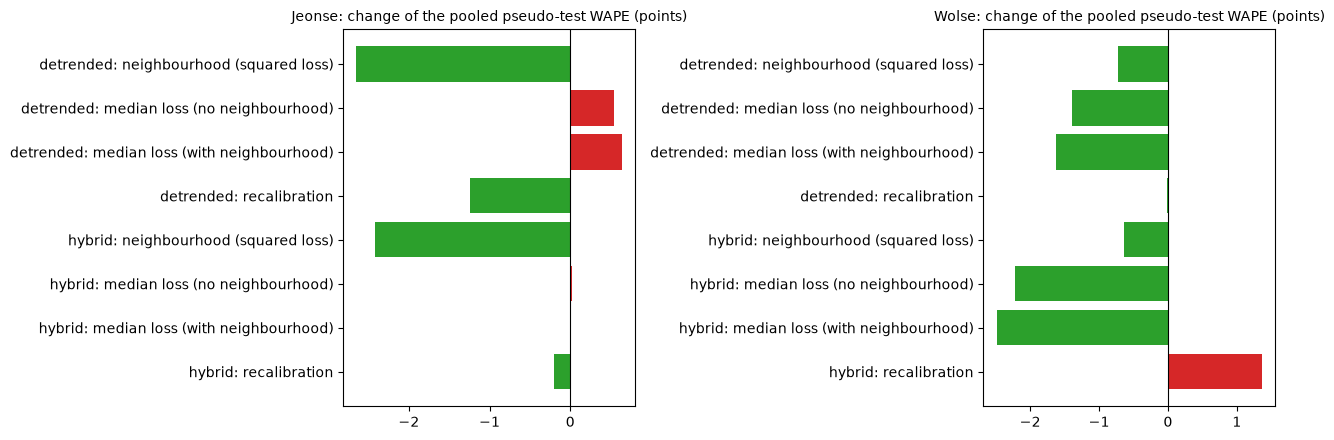

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=False)
for ax, track in zip(axes, config.TRACKS):
    sub = components.loc[track].reset_index()
    labels = sub['family'].str.replace(' family', '') + ': ' + sub['component']
    ax.barh(labels[::-1], sub['pooled change (pts)'][::-1], color=['tab:green' if v < 0 else 'tab:red' for v in sub['pooled change (pts)'][::-1]])
    ax.axvline(0, color='k', lw=0.8); ax.set_title(f'{track.capitalize()}: change of the pooled pseudo-test WAPE (points)', fontsize=10)
plt.tight_layout(); plt.savefig(config.FIGURES_DIR / '11_component_effects.png', dpi=130); plt.show()

**Interpretation.** The figure shows the change of the pooled pseudo-test WAPE caused by each component (green is an improvement). In Jeonse the neighbourhood is the only large improvement; in Wolse the median loss and the neighbourhood both improve and the recalibration is neutral or negative.

## Save the new runs and the selection report (written only after every analysis above has run)

In [16]:
for track in config.TRACKS:
    d = data[track]
    for model_id in NEW:
        rec = final_recipes[(track, model_id)]
        key = 'structure_params' if model_id.startswith('hybrid') else 'params'
        meta = {'base_model': model_id.removesuffix('_recal'), 'loss': 'quantile 0.5 on log1p' if '_median' in model_id else 'squared error on log1p',
                key: rec.params, 'tuning': 'RandomizedSearchCV, 3-fold expanding window inside the fit window (rows before 2025-01-01), median-loss finalist of the family',
                'fit_period': '2022-01-01..2024-12-31', 'eval_period': '2025', 'neighbourhood': True, 'recalibrated': rec.recal,
                'recal_factor': rec.recal_factor_ if rec.recal else None, 'behaviour': behaviour[(track, model_id)],
                'pseudo_test_wape': {w: pseudo[track][model_id][w]['metrics']['wape_pct'] for w in ('2023', '2024')}}
        save_run(track, model_id, d['test'][d['target']], final_pred[(track, model_id)], meta=meta, context=d['test'][['district_name', 'contract_date']])
print('saved', len(NEW) * len(config.TRACKS), 'new runs:', NEW)

for track in config.TRACKS:
    cand = {}
    for model_id in pseudo[track]:
        row = pooled[track].loc[model_id]
        cand[model_id] = {'wape_2023': float(row['wape_2023']), 'wape_2024': float(row['wape_2024']), 'wape_pooled': float(row['wape_pooled']),
                          'behaviour': behaviour[(track, model_id)], 'complexity': complexity_of(model_id),
                          'annual_means': {str(k): float(v) for k, v in annual[(track, model_id)].items()}}
    sel = selection[track]
    report = {'protocol': {'windows': [{'fit_before': f"{w['fit_end']:%Y-%m-%d}", 'test_year': w['test_year']} for w in WINDOWS],
                           'rule': 'one-standard-error with the most conservative of row, month-block and district-block bootstrap SE',
                           'tie_break': 'fewer parameters (complexity level), then smaller absolute aggregate bias',
                           'settings': 'tuned inside each fit window (RandomizedSearchCV, 3-fold expanding window)'},
              'candidates': cand,
              'selection': {'unconstrained': sel['unconstrained'], 'extrapolating': sel['extrapolating'],
                            'previous_unconstrained': previous[track]['unconstrained'], 'previous_extrapolating': previous[track]['extrapolating'],
                            'tie_set_unconstrained': list(sel['table_all'][sel['table_all']['tie_with_leader']]['model_id']),
                            'tie_set_extrapolating': list(sel['table_ext'][sel['table_ext']['tie_with_leader']]['model_id'])},
              'table_unconstrained': json.loads(sel['table_all'].to_json(orient='records')),
              'table_extrapolating': json.loads(sel['table_ext'].to_json(orient='records'))}
    path = config.METRICS_DIR / f'pseudotest_v2_{track}.json'
    path.write_text(json.dumps(report, indent=1), encoding='utf-8')
    print('written', path.relative_to(config.ROOT))

saved 12 new runs: ['hgb_detrended_ld', 'hgb_detrended_ld_median', 'hybrid_hgb_ld', 'hybrid_hgb_ld_median', 'hgb_detrended_ld_median_recal', 'hybrid_hgb_ld_median_recal']
written reports\metrics\pseudotest_v2_jeonse.json
written reports\metrics\pseudotest_v2_wolse.json


## Summary

## Conclusion

- **New winners.** Jeonse: `hgb_detrended_ld_median_recal` (pooled pseudo-test WAPE 15.0935%, 2025 WAPE 14.1366%). Wolse: `hgb_detrended_ld_median` (39.2291% and 40.7950%). Both extrapolate through the log-linear trend, so the requirement costs nothing under the pseudo-test protocol.
- **Components.** The neighbourhood is the main gain in Jeonse (about -2.4 to -2.9 points); the median loss and the neighbourhood both matter in Wolse (about -1.5 and -3.0 points on 2025); the recalibration helps Jeonse a little and is unstable in Wolse because its factor comes from a short last fold.
- **Repeat units** have a lower error than new units for all shortlisted models, but the gains of the neighbourhood-aware models also appear on new units.
- **More history helps:** 12-month fits are worse than 24-month fits for every model in the second pseudo-test window.
- **Limits.** 12 candidates per search with several best settings at the grid edge; the Jeonse trend of the winner is a log-linear extrapolation of 48 months (its annual mean rises 15.0132% between 2026 and 2028); 2025 was inspected in earlier iterations.